In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('HeightWeight1.csv')
df.head()

,Weight,Height
0,51.25,167.09
1,61.91,181.65
2,69.41,176.27
3,64.56,173.27
4,65.45,172.18


Text(0.5, 1.0, 'Height and Weight Scatter Graph')

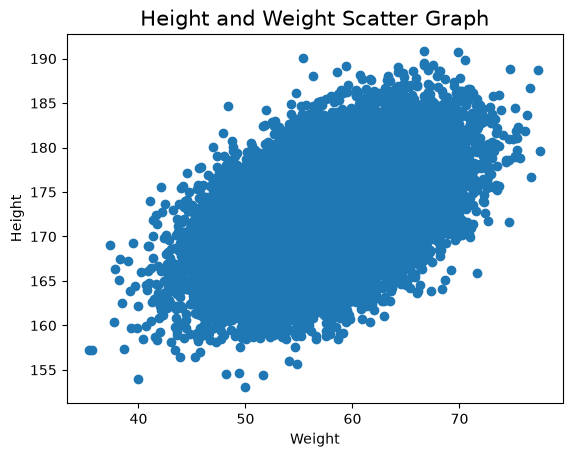

In [3]:
plt.scatter(df['Weight'],df['Height'])
plt.xlabel("Weight")
plt.ylabel("Height")
plt.title("Height and Weight Scatter Graph",fontsize=15)


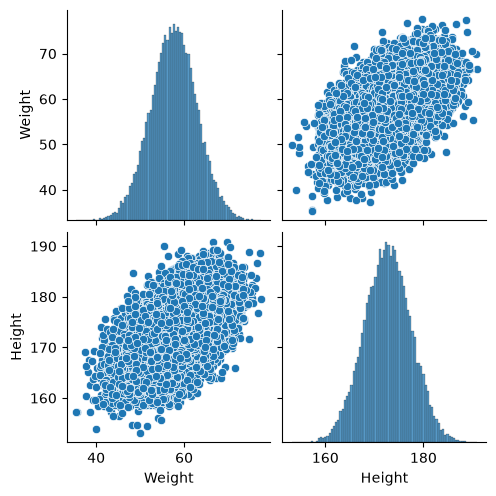

In [4]:
sns.pairplot(df)

In [5]:
X = df[['Weight']]
y = df['Height']


In [6]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)


In [7]:
y_train


23311    172.59
23623    169.05
1020     177.93
12645    173.94
1533     167.92
          ...  
21575    171.42
5390     169.99
860      173.72
15795    176.01
23654    170.51
Name: Height, Length: 20000, dtype: float64

In [8]:
y_test


6868     173.80
24016    172.46
9668     171.85
13640    175.29
14018    175.29
          ...  
8670     175.10
11839    170.90
4013     174.17
21147    170.42
695      179.25
Name: Height, Length: 5000, dtype: float64

In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test_test = scaler.transform(X_test)

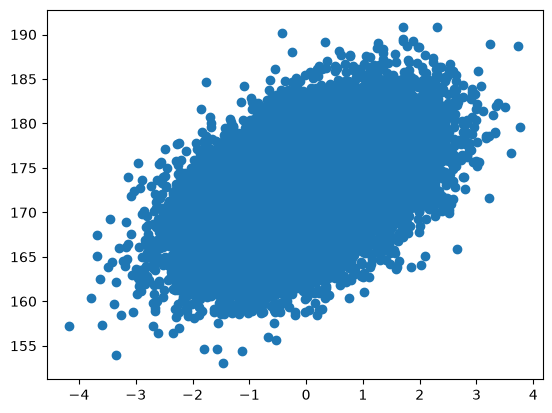

In [10]:
plt.scatter(X_train,y_train)

In [11]:
from sklearn.linear_model import LinearRegression

In [12]:
linear = LinearRegression()

In [13]:
linear

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [14]:
type(X_train)



numpy.ndarray

In [15]:
X_train=np.array(X_train).reshape(-1,1)
X_test=np.array(X_test).reshape(-1,1)

In [16]:
y_train.shape

(20000,)

In [17]:
linear.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2.41]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,172.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[141.42]


In [18]:
print("Coefficient : ",linear.coef_)
print("Intercept : ",linear.intercept_)

Coefficient :  [2.41355168]
Intercept :  172.6954815


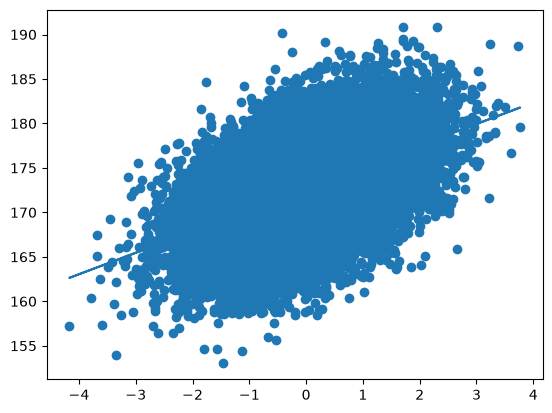

In [19]:
plt.scatter(X_train,y_train)
plt.plot(X_train,linear.predict(X_train))

### prediction of train data
1. predicted height output= intercept +coef_(Weights)
2. y_pred_train =65.4364 + 1.26(X_train)
          
### prediction of test data
1. predicted height output= intercept +coef_(Weights)
2. y_pred_test =65.4364 + 1.26(X_test)

In [20]:
y_pred_test=linear.predict(X_test)

In [21]:
y_test

6868     173.80
24016    172.46
9668     171.85
13640    175.29
14018    175.29
          ...  
8670     175.10
11839    170.90
4013     174.17
21147    170.42
695      179.25
Name: Height, Length: 5000, dtype: float64

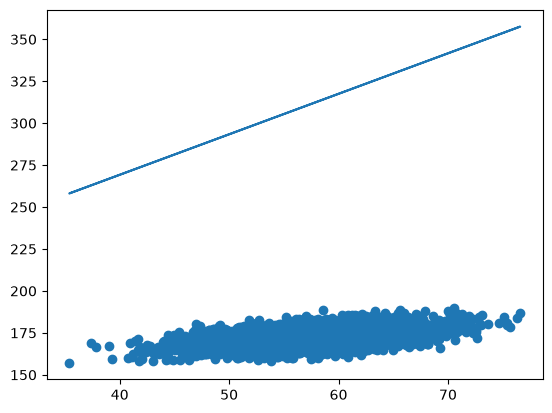

In [22]:
plt.scatter(X_test,y_test)
plt.plot(X_test,linear.predict(X_test))

In [23]:
### Performance metrics

from sklearn.metrics import mean_squared_error,mean_absolute_error

In [24]:
mse=mean_squared_error(y_test,y_pred_test)
mae=mean_absolute_error(y_test,y_pred_test)
rmse=np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

19472.536959160465
139.09281749096706
139.54403233087564


In [25]:
from sklearn.metrics import r2_score
score=r2_score(y_test,y_pred_test)

In [26]:
print(score)

-818.0247722478689


## R square 
Formula

**R^2 = 1 - SSR/SST**


R^2	=	coefficient of determination
SSR	=	sum of squares of residuals
SST	=	total sum of squares

In [27]:
from sklearn.metrics import r2_score
score=r2_score(y_test,y_pred_test)
print(score)

-818.0247722478689


**Adjusted R2 = 1 – [(1-R2)*(n-1)/(n-k-1)]**

where:

R2: The R2 of the model
n: The number of observations
k: The number of predictor variables

In [28]:
#display adjusted R-squared
1 - (1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

-818.1886427505195

In [29]:
linear.predict(scaler.transform([[100]]))

C:\Users\adbhu\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([192.0713818])

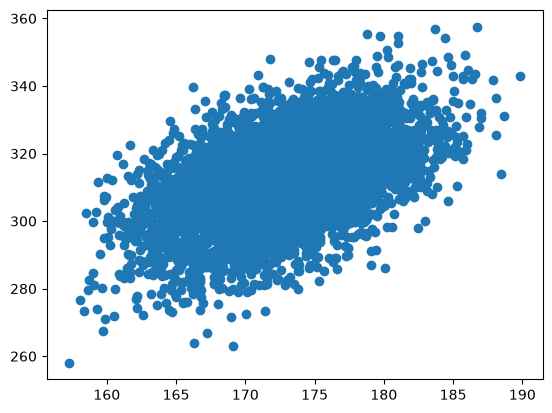

In [30]:
plt.scatter(y_test,y_pred_test)


In [31]:
## Residuals
residuals=y_test-y_pred_test

residuals



6868    -145.904914
24016   -122.819771
9668    -149.713349
13640   -135.774399
14018   -107.077270
            ...    
8670    -148.780359
11839   -116.970168
4013    -153.089331
21147   -144.071643
695     -140.961760
Name: Height, Length: 5000, dtype: float64

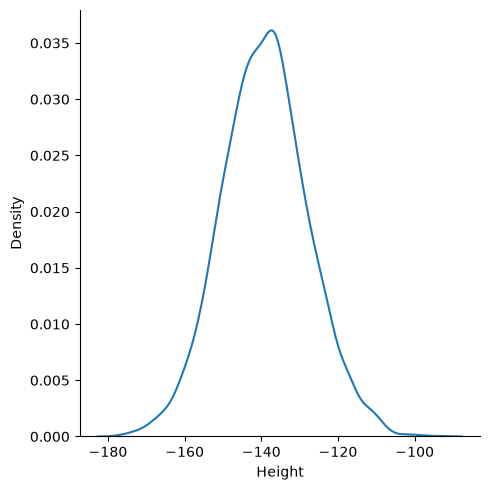

In [32]:
## Plot this residuals 
import seaborn as sns
sns.displot(residuals,kind="kde")



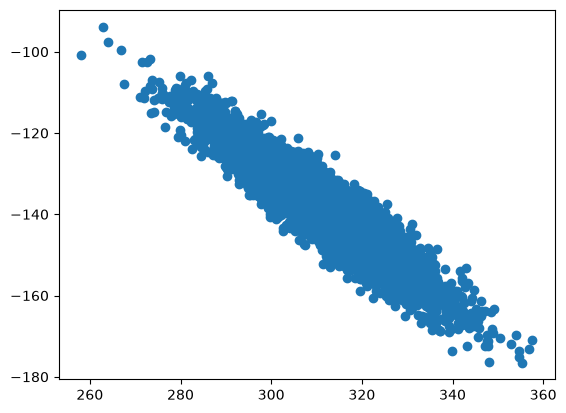

In [33]:
## Scatter plot with respect to prediction and residuals
## uniform distribution
plt.scatter(y_pred_test,residuals)

In [34]:
%pip install statsmodels
import statsmodels.api as sm


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\adbhu\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [35]:

model = sm.OLS(y_train, X_train).fit()
predictions = model.predict(X_test) 

In [36]:
print(model.summary())


                                 OLS Regression Results                                
Dep. Variable:                 Height   R-squared (uncentered):                   0.000
Model:                            OLS   Adj. R-squared (uncentered):              0.000
Method:                 Least Squares   F-statistic:                              3.904
Date:                Wed, 07 Oct 2026   Prob (F-statistic):                      0.0482
Time:                        15:56:44   Log-Likelihood:                     -1.3142e+05
No. Observations:               20000   AIC:                                  2.628e+05
Df Residuals:                   19999   BIC:                                  2.628e+05
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [37]:
linear.coef_


array([2.41355168])